# Análise de Viagens a Serviço — Governo Federal (2025)

## Projeto Avaliativo — Análise de Dados com Python

### Objetivo

Analisar dados públicos de viagens a serviço do Governo Federal
referentes ao ano de 2025, utilizando Python, PostgreSQL e técnicas
de análise e visualização de dados.

### Arquitetura do projeto

O processamento dos dados segue três camadas:

- **Raw:** armazenamento dos dados originais extraídos dos arquivos CSV.
- **Silver:** dados tratados, tipados e organizados com regras de integridade.
- **Gold:** dados agregados para responder às perguntas de negócio.

### Ferramentas utilizadas

- Python
- PostgreSQL
- pandas
- Matplotlib
- Jupyter Notebook

### Etapas da análise

1. Verificação dos dados disponíveis.
2. Criação da camada Gold.
3. Resolução das sete perguntas de negócio.
4. Construção de gráficos.
5. Interpretação dos resultados.

In [1]:
import sys

print("Python em uso:", sys.executable)
print("Ambiente virtual configurado com sucesso!")

Python em uso: c:\Users\gatsu\Documents\projetos\sctec.tad\Projeto_Final_CaioCorrea_Analise_de_Dados_T5\.venv\Scripts\python.exe
Ambiente virtual configurado com sucesso!


In [2]:
from banco import conectar

with conectar() as conexao, conexao.cursor() as cursor:
    cursor.execute("SELECT current_database(), version()")
    resultado = cursor.fetchone()

print("Banco conectado:", resultado[0])
print("PostgreSQL:", resultado[1].split(",")[0])

Banco conectado: transparencia
PostgreSQL: PostgreSQL 18.6 on x86_64-windows


In [3]:
import pandas as pd

consulta = """
SELECT 'Viagens' AS tabela, COUNT(*) AS registros
FROM silver_viagem

UNION ALL

SELECT 'Pagamentos', COUNT(*)
FROM silver_pagamento

UNION ALL

SELECT 'Passagens', COUNT(*)
FROM silver_passagem

UNION ALL

SELECT 'Trechos', COUNT(*)
FROM silver_trecho;
"""

with conectar() as conexao, conexao.cursor() as cursor:
    cursor.execute(consulta)
    dados = cursor.fetchall()
    colunas = [coluna[0] for coluna in cursor.description]

resumo_silver = pd.DataFrame(dados, columns=colunas)

display(resumo_silver)

,tabela,registros
0,Passagens,167260
1,Viagens,341860
2,Pagamentos,606916
3,Trechos,763349


## Pergunta 1 — Quais são os cinco órgãos com maior gasto total em viagens?

Nesta análise, identificamos os cinco órgãos superiores com os maiores
gastos em viagens a serviço durante 2025.

Os valores são obtidos da tabela `silver_viagem`, agrupados por órgão
superior e ordenados pelo gasto total em ordem decrescente.

In [4]:
consulta_1 = """
SELECT
    nome_orgao_superior AS orgao,
    COUNT(*) AS quantidade_viagens,
    SUM(valor_total) AS gasto_total
FROM silver_viagem
GROUP BY nome_orgao_superior
ORDER BY gasto_total DESC
LIMIT 5;
"""

with conectar() as conexao, conexao.cursor() as cursor:
    cursor.execute(consulta_1)
    resultados = cursor.fetchall()
    colunas = [coluna[0] for coluna in cursor.description]

top_5_orgaos = pd.DataFrame(resultados, columns=colunas)

display(top_5_orgaos)

,orgao,quantidade_viagens,gasto_total
0,Ministério da Justiça e Segurança Pública,75742,486933121.65
1,Ministério da Defesa,61912,156070304.49
2,Ministério da Educação,65295,111291349.34
3,Ministério do Meio Ambiente e Mudança do Clima,19413,49697710.16
4,Ministério da Previdência Social,8190,40417309.06


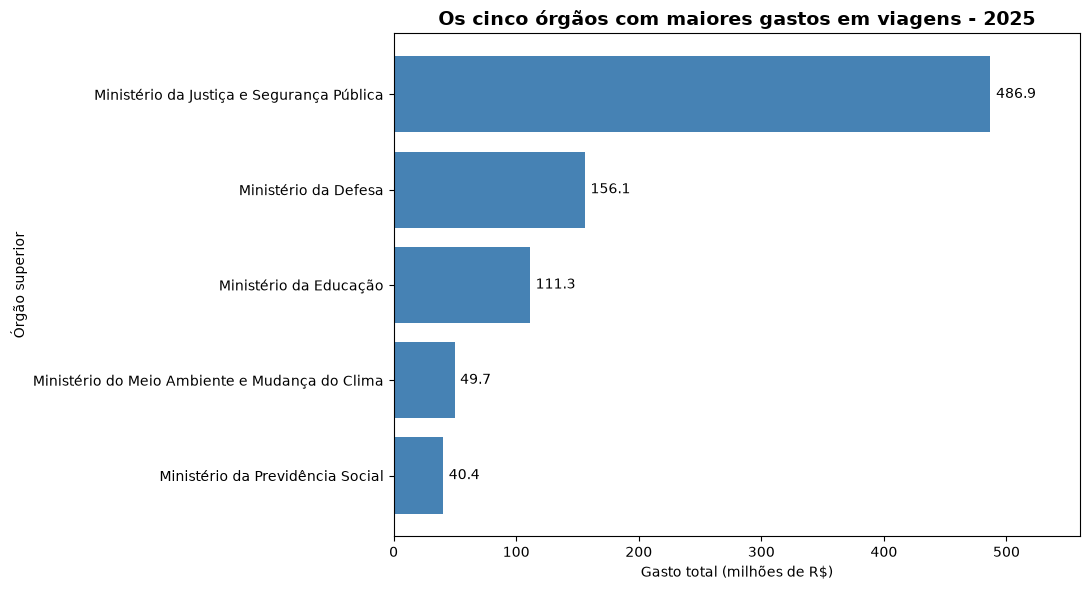

In [5]:
import matplotlib.pyplot as plt

# Preparar os valores para visualizacao em milhoes de reais.
dados_grafico = top_5_orgaos.copy()
dados_grafico["gasto_milhoes"] = (
    dados_grafico["gasto_total"].astype(float) / 1_000_000
)

# Criar o grafico.
fig, ax = plt.subplots(figsize=(11, 6))

barras = ax.barh(
    dados_grafico["orgao"],
    dados_grafico["gasto_milhoes"],
    color="steelblue",
)

# Exibir o maior gasto na parte superior.
ax.invert_yaxis()

# Configurar titulo e eixos.
ax.set_title(
    "Os cinco órgãos com maiores gastos em viagens - 2025",
    fontsize=14,
    fontweight="bold",
)

ax.set_xlabel("Gasto total (milhões de R$)")
ax.set_ylabel("Órgão superior")

# Exibir os valores ao lado das barras.
ax.bar_label(
    barras,
    fmt="%.1f",
    padding=4,
)

ax.set_xlim(0, dados_grafico["gasto_milhoes"].max() * 1.15)

plt.tight_layout()
plt.show()

### Interpretação dos resultados

O Ministério da Justiça e Segurança Pública apresentou o maior gasto
total em viagens a serviço em 2025, com aproximadamente R$ 486,9 milhões.

O Ministério da Defesa ficou na segunda posição, com R$ 156,1 milhões,
seguido pelo Ministério da Educação, com R$ 111,3 milhões.

O gasto do Ministério da Justiça e Segurança Pública foi aproximadamente
3,1 vezes superior ao do Ministério da Defesa.

Os resultados demonstram uma concentração dos gastos em determinados
órgãos federais. Entretanto, os valores isolados não permitem avaliar
a eficiência dessas despesas, pois seria necessário considerar as
atribuições e necessidades operacionais de cada órgão.

## Pergunta 2 — Quais são os três destinos com maior custo médio de viagem?

Esta análise identifica os três destinos registrados com maior custo
médio de viagem em 2025.

O custo médio é calculado dividindo o gasto total pela quantidade de
viagens associadas a cada destino.

**Critério:** o campo `destinos` é analisado conforme registrado na
base de dados, sem separar viagens com múltiplas localidades.

In [6]:
consulta_2 = """
SELECT
    destinos AS destino,
    COUNT(*) AS quantidade_viagens,
    ROUND(AVG(valor_total), 2) AS custo_medio
FROM silver_viagem
WHERE destinos IS NOT NULL
  AND TRIM(destinos) <> ''
GROUP BY destinos
ORDER BY custo_medio DESC
LIMIT 3;
"""

with conectar() as conexao, conexao.cursor() as cursor:
    cursor.execute(consulta_2)
    resultados = cursor.fetchall()
    colunas = [coluna[0] for coluna in cursor.description]

top_3_destinos = pd.DataFrame(resultados, columns=colunas)

display(top_3_destinos)

,destino,quantidade_viagens,custo_medio
0,"Abu Dabi/Emirados Árabes, Riad/Arábia Saudita,...",1,245852.80
1,"Brasília/DF, Rio Branco/AC, Cruzeiro do Sul/AC...",1,216729.36
2,"Brasília/DF, Rio de Janeiro/RJ, Angra dos Reis...",1,207220.14


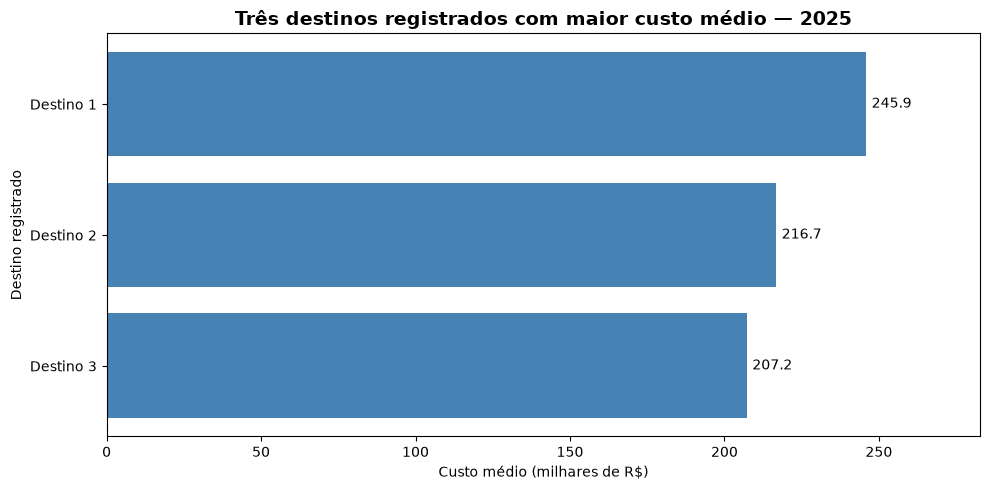

In [7]:
# Preparar os dados para o gráfico.
dados_destinos = top_3_destinos.copy()

dados_destinos["custo_medio"] = dados_destinos["custo_medio"].astype(float)

# Utilizar identificadores curtos para facilitar a leitura.
dados_destinos["identificador"] = [
    f"Destino {i + 1}" for i in range(len(dados_destinos))
]

# Criar o gráfico.
fig, ax = plt.subplots(figsize=(10, 5))

barras = ax.barh(
    dados_destinos["identificador"],
    dados_destinos["custo_medio"] / 1_000,
    color="steelblue",
)

ax.invert_yaxis()

ax.set_title(
    "Três destinos registrados com maior custo médio — 2025",
    fontsize=14,
    fontweight="bold",
)

ax.set_xlabel("Custo médio (milhares de R$)")
ax.set_ylabel("Destino registrado")

ax.bar_label(barras, fmt="%.1f", padding=4)

ax.set_xlim(0, dados_destinos["custo_medio"].max() / 1_000 * 1.15)

plt.tight_layout()
plt.show()

### Interpretação dos resultados

A análise identificou os três itinerários registrados com os maiores
custos médios de viagem em 2025.

O primeiro apresentou custo médio de aproximadamente R$ 245,9 mil,
seguido pelo segundo, com R$ 216,7 mil, e pelo terceiro, com R$ 207,2 mil.

Entretanto, cada um desses itinerários possui apenas uma viagem
registrada. Portanto, nesses casos, o custo médio corresponde ao
valor total de uma única viagem.

Além disso, o campo `destinos` pode conter múltiplas localidades,
representando um itinerário completo, e não uma cidade isolada.

Assim, os resultados identificam os itinerários de maior custo médio
na base, mas não permitem concluir quais cidades apresentam,
de maneira geral, os maiores custos de viagem.

## Pergunta 3 — Qual foi a viagem de maior duração e quanto ela custou?

Esta análise identifica a viagem com maior duração registrada na base
de dados de 2025.

A duração é calculada considerando a diferença entre a data de término
e a data de início, incluindo ambos os dias.

Também são apresentados o órgão responsável, o viajante, o destino
registrado e o custo total da viagem.

In [8]:
consulta_3 = """
SELECT
    id_viagem,
    nome_orgao_superior AS orgao,
    nome_viajante AS viajante,
    destinos AS destino,
    data_inicio,
    data_fim,
    duracao_dias,
    valor_total AS custo_total
FROM silver_viagem
WHERE duracao_dias IS NOT NULL
ORDER BY duracao_dias DESC, valor_total DESC, id_viagem
LIMIT 1;
"""

with conectar() as conexao, conexao.cursor() as cursor:
    cursor.execute(consulta_3)
    resultados = cursor.fetchall()
    colunas = [coluna[0] for coluna in cursor.description]

viagem_mais_longa = pd.DataFrame(resultados, columns=colunas)

display(viagem_mais_longa)

,id_viagem,orgao,viajante,destino,data_inicio,data_fim,duracao_dias,custo_total
0,0000000000020699856,Ministério da Previdência Social,LUISANGELA CORREA FRANCO DE FARIA,Mogi Mirim/SP,2025-01-13,2026-01-31,384,0.00


### Interpretação dos resultados

A viagem de maior duração identificada na base de dados de 2025
foi registrada pelo Ministério da Previdência Social, com destino
a Mogi Mirim/SP.

O período informado compreende 13 de janeiro de 2025 a
31 de janeiro de 2026, totalizando 384 dias, considerando
as datas inicial e final.

Apesar da duração elevada, o custo total registrado na camada
Silver foi de R$ 0,00.

O resultado demonstra que a duração de uma viagem não está
necessariamente associada a um gasto elevado nos registros
analisados.

Além disso, a viagem ultrapassa o ano de 2025, indicando que
a base pode conter deslocamentos com término no ano seguinte.

O valor zero deve ser interpretado como ausência de gastos
registrados nos campos utilizados no cálculo, e não como
comprovação de que não houve despesas relacionadas à viagem.

## Pergunta 4 — Qual tipo de pagamento apresenta o maior valor médio?

Esta análise compara os valores médios dos diferentes tipos de pagamento
registrados nas viagens a serviço em 2025.

Para cada modalidade, são apresentados a quantidade de pagamentos,
o valor médio e o valor total movimentado.

O cálculo considera os registros individuais da tabela `silver_pagamento`.

In [9]:
consulta_4 = """
SELECT
    tipo_pagamento,
    COUNT(*) AS quantidade_pagamentos,
    ROUND(AVG(valor), 2) AS valor_medio,
    ROUND(SUM(valor), 2) AS valor_total
FROM silver_pagamento
WHERE tipo_pagamento IS NOT NULL
GROUP BY tipo_pagamento
ORDER BY valor_medio DESC;
"""

with conectar() as conexao, conexao.cursor() as cursor:
    cursor.execute(consulta_4)
    resultados = cursor.fetchall()
    colunas = [coluna[0] for coluna in cursor.description]

media_por_pagamento = pd.DataFrame(resultados, columns=colunas)

display(media_por_pagamento)

,tipo_pagamento,quantidade_pagamentos,valor_medio,valor_total
0,DIÁRIAS,401463,2078.28,834352643.52
1,PASSAGEM,188985,1878.34,354978915.13
2,Serviço correlato: seguro,4894,447.51,2190136.71
3,RESTITUIÇÃO,11574,245.70,2843762.01


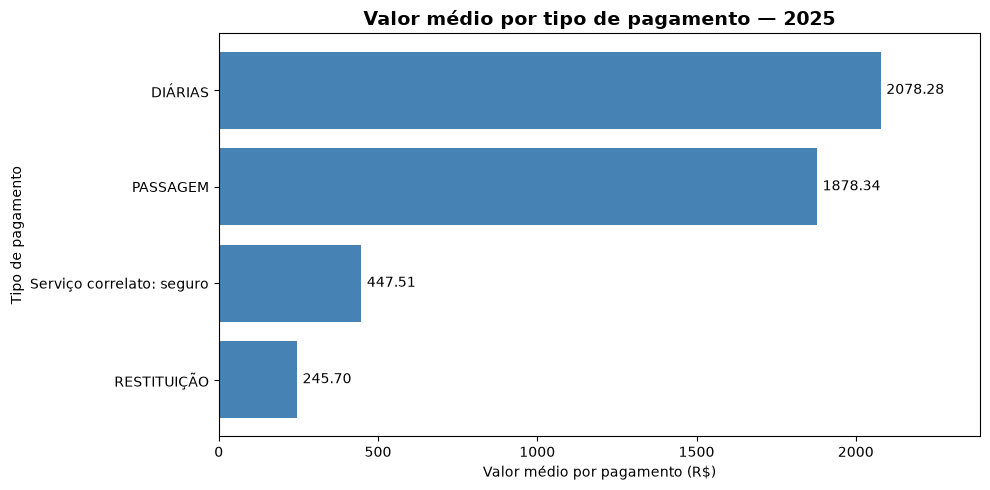

In [10]:
# Preparar os dados para o gráfico.
dados_pagamentos = media_por_pagamento.copy()
dados_pagamentos["valor_medio"] = dados_pagamentos["valor_medio"].astype(float)

# Criar o gráfico.
fig, ax = plt.subplots(figsize=(10, 5))

barras = ax.barh(
    dados_pagamentos["tipo_pagamento"],
    dados_pagamentos["valor_medio"],
    color="steelblue",
)

# Apresentar o maior valor na parte superior.
ax.invert_yaxis()

# Configurar título e eixos.
ax.set_title(
    "Valor médio por tipo de pagamento — 2025",
    fontsize=14,
    fontweight="bold",
)

ax.set_xlabel("Valor médio por pagamento (R$)")
ax.set_ylabel("Tipo de pagamento")

# Apresentar os valores ao lado das barras.
ax.bar_label(barras, fmt="%.2f", padding=4)

ax.set_xlim(0, dados_pagamentos["valor_medio"].max() * 1.15)

plt.tight_layout()
plt.show()

### Interpretação dos resultados

A análise dos pagamentos relacionados às viagens a serviço em 2025
identificou que a modalidade DIÁRIAS apresentou o maior valor médio
por pagamento, aproximadamente R$ 2.078,28, considerando 401.463 registros.

A modalidade PASSAGEM ficou na segunda posição, com valor médio de
R$ 1.878,34 e 188.985 registros.

Os pagamentos classificados como Serviço correlato: seguro apresentaram
média de R$ 447,51, enquanto a modalidade RESTITUIÇÃO registrou
o menor valor médio, de R$ 245,70.

Os resultados demonstram diferenças entre os valores médios das
modalidades. Entretanto, é importante observar que a análise considera
pagamentos individuais, e não o custo médio total de cada viagem.

Além disso, o valor médio não representa necessariamente o custo
mais frequente, pois pagamentos de valores elevados podem influenciar
a média.